# Drone Detection & Tracking — YOLO11 + ByteTrack

Runtime: T4 GPU.

In [ ]:
%cd /content
!rm -rf drone-detection-tracking
!git clone -q https://github.com/semanur-s/drone-detection-tracking.git
%cd /content/drone-detection-tracking
!pip install -q -r requirements.txt

import os, random, shutil, json
from pathlib import Path
import cv2, matplotlib.pyplot as plt
os.makedirs('assets', exist_ok=True)
IMG_EXT = {'.jpg', '.jpeg', '.png', '.bmp', '.webp'}

## 1. Data

In [ ]:
!python src/prepare_data.py --train-batches 1 --test-batches 1 --max-train 8000 --max-test 2000 --out data

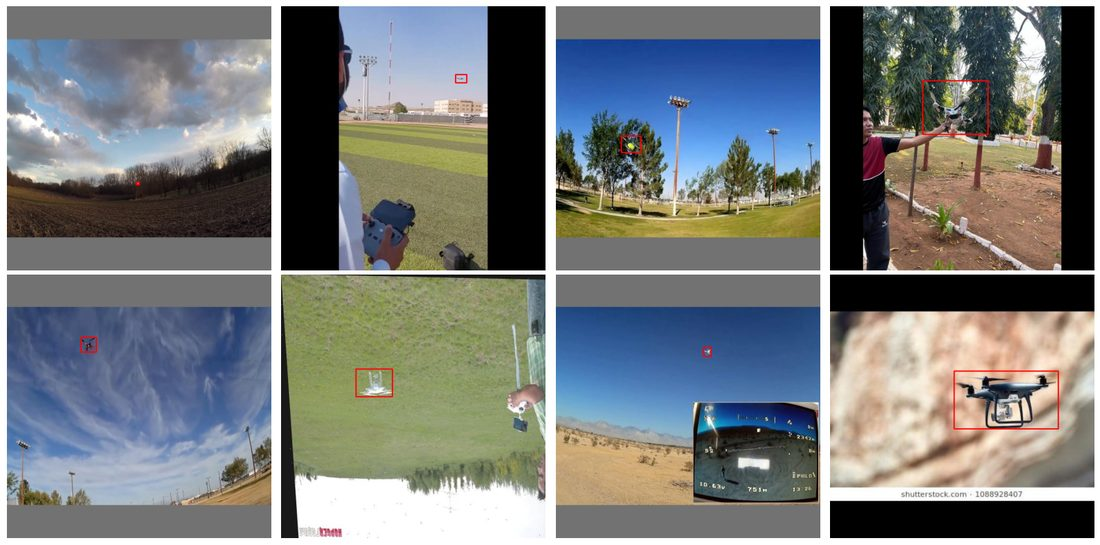

In [ ]:
imgs = sorted(p for p in Path('data/drone/train/images').iterdir() if p.suffix.lower() in IMG_EXT)
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for ax, p in zip(axes.ravel(), random.Random(0).sample(imgs, 8)):
    im = cv2.cvtColor(cv2.imread(str(p)), cv2.COLOR_BGR2RGB); h, w = im.shape[:2]
    lbl = p.parent.parent / 'labels' / (p.stem + '.txt')
    for line in (lbl.read_text().splitlines() if lbl.exists() else []):
        _, cx, cy, bw, bh = map(float, line.split())
        x1, y1 = int((cx - bw/2) * w), int((cy - bh/2) * h)
        cv2.rectangle(im, (x1, y1), (int(x1 + bw*w), int(y1 + bh*h)), (255, 0, 0), 2)
    ax.imshow(im); ax.axis('off')
plt.tight_layout(); plt.savefig('assets/ornek_veriler.png', dpi=100); plt.show()

## 2. Training

...
      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
      46/50      2.83G      1.056     0.5268      1.134         16        640: 100% ━━━━━━━━━━━━ 450/450 4.5it/s 1:41
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 25/25 4.1it/s 6.1s
                   all        800        837      0.942      0.926      0.953      0.644
      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
      47/50      2.83G      1.048     0.5169      1.127         16        640: 100% ━━━━━━━━━━━━ 450/450 4.4it/s 1:42
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 25/25 4.1it/s 6.1s
                   all        800        837      0.946      0.926      0.952      0.638
      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
      48/50      2.83G      1.032     0.5081      1.121         16        640: 100% ━━━━━━━━━━

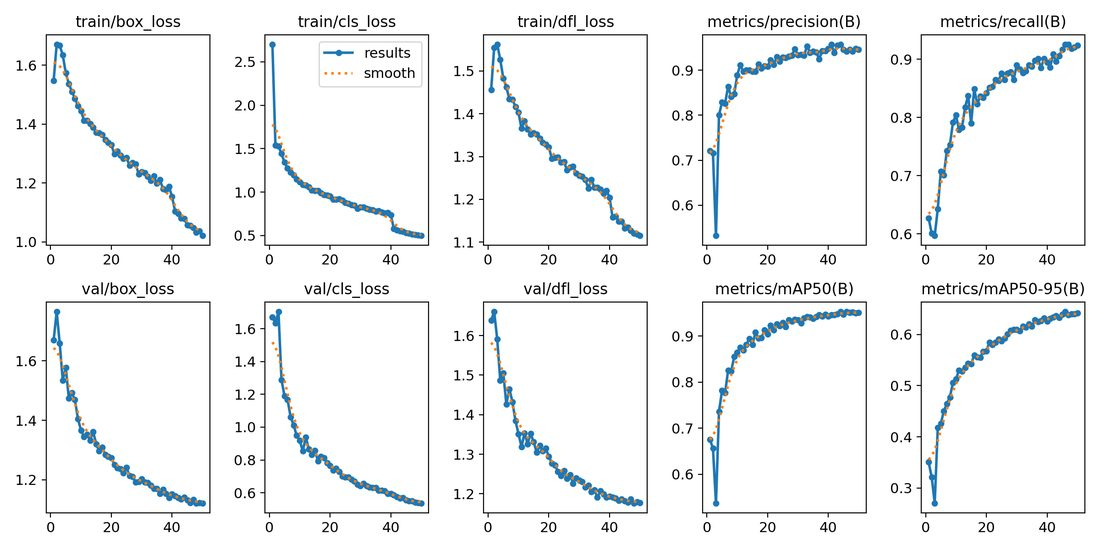

In [ ]:
!python src/train.py --data data/drone.yaml --model yolo11n.pt --epochs 50 --imgsz 640 --batch 16 --device 0
WEIGHTS = open('results/best_weights.txt').read().strip()
run_dir = Path(WEIGHTS).parent.parent
shutil.copy(run_dir / 'results.png', 'assets/egitim_egrileri.png')
from IPython.display import Image, display
display(Image('assets/egitim_egrileri.png', width=1000))

## 3. Evaluation

In [ ]:
!python src/evaluate.py --weights $WEIGHTS --data data/drone.yaml

Ultralytics 8.4.218 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 101 layers, 2,597,051 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2130.6±789.7 MB/s, size: 103.4 KB)
                   all       2000       2065      0.927      0.828      0.889      0.576
Speed: 1.4ms preprocess, 3.8ms inference, 0.0ms loss, 1.8ms postprocess per image
Results saved to /content/drone-detection-tracking/runs/detect/test_eval
{
  "precision": 0.9270673025794216,
  "recall": 0.8280871670702179,
  "mAP50": 0.8894584210880618,
  "mAP50_95": 0.5755194201772895,
  "boyuta_gore": {
    "kucuk (<32px)": {
      "adet": 446,
      "recall": 0.9147982062780269
    },
    "orta (32-96px)": {
      "adet": 710,
      "recall": 0.856338028169014
    },
    "buyuk (>96px)": {
      "adet": 909,
      "recall": 0.8316831683168316
    }
  }
}


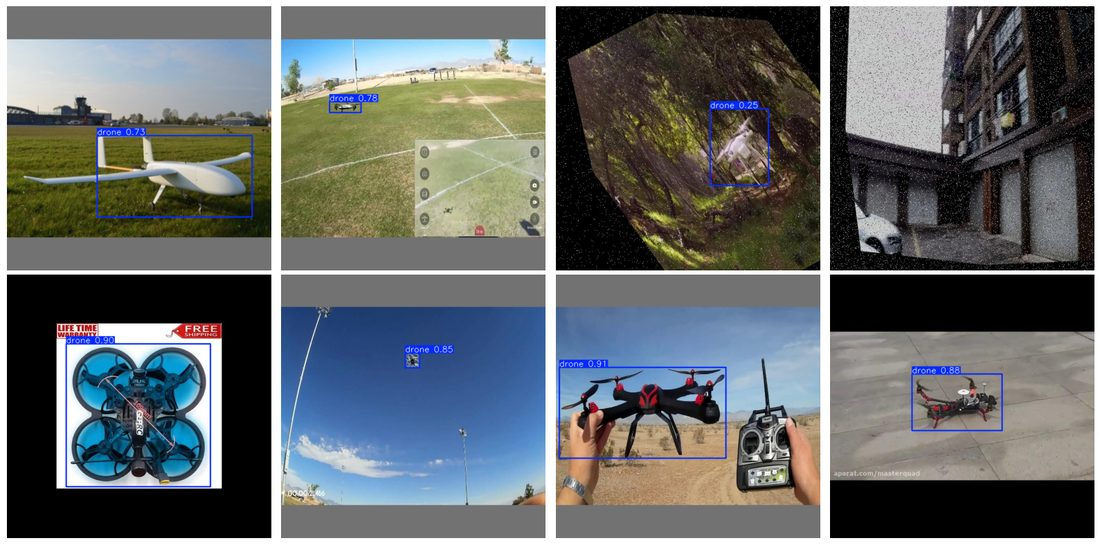

In [ ]:
from ultralytics import YOLO
model = YOLO(WEIGHTS)
test_imgs = sorted(p for p in Path('data/drone/test/images').iterdir() if p.suffix.lower() in IMG_EXT)
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for ax, p in zip(axes.ravel(), random.Random(1).sample(test_imgs, 8)):
    r = model.predict(str(p), conf=0.25, verbose=False)[0]
    ax.imshow(cv2.cvtColor(r.plot(), cv2.COLOR_BGR2RGB)); ax.axis('off')
plt.tight_layout(); plt.savefig('assets/test_tahminleri.png', dpi=100); plt.show()
for src, dst in [('confusion_matrix.png', 'confusion_matrix.png'), ('BoxPR_curve.png', 'pr_egrisi.png')]:
    p = Path('runs/detect/test_eval') / src
    if p.exists(): shutil.copy(p, f'assets/{dst}')

## 4. Tracking
Upload a video showing a drone in flight.

In [ ]:
from google.colab import files
up = files.upload()
VIDEO = list(up.keys())[0]

{
  "kare_sayisi": 450,
  "iz_sayisi": 1,
  "ortalama_iz_uzunlugu_kare": 450.0,
  "ortalama_fps": 43.2
}


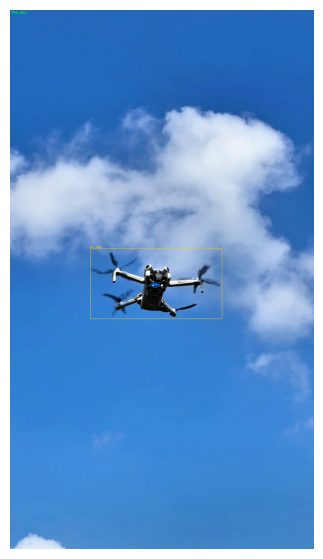

In [ ]:
!python src/track.py --weights $WEIGHTS --source "$VIDEO" --tracker configs/bytetrack_drone.yaml
cap = cv2.VideoCapture('results/tracked.mp4'); n = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
cap.set(cv2.CAP_PROP_POS_FRAMES, n // 2); ok, frame = cap.read(); cap.release()
cv2.imwrite('assets/takip_karesi.jpg', frame)
plt.figure(figsize=(12, 7)); plt.imshow(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)); plt.axis('off'); plt.show()

## 5. ONNX export & CPU benchmark

In [ ]:
!python src/export_benchmark.py --weights $WEIGHTS --images data/drone/test/images --n 100

Ultralytics 8.4.218 🚀 Python-3.13.16 torch-2.14.1+cu130 CPU (Intel Xeon CPU @ 2.00GHz)
YOLO11n summary (fused): 101 layers, 2,597,051 parameters, 0 gradients, 6.4 GFLOPs
PyTorch: starting from '/content/drone-detection-tracking/runs/detect/drone_yolo11n/weights/best.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) (1, 5, 8400) (5.3 MB)
requirements: Ultralytics requirement ['onnxslim>=0.1.82'] not found, attempting AutoUpdate...
Using Python 3.13.16 environment at: /usr
Resolved 10 packages in 265ms
Prepared 2 packages in 28ms
Installed 2 packages in 8ms
 + colorama==0.4.6
 + onnxslim==0.1.99
requirements: AutoUpdate success ✅ 0.7s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect
ONNX: starting export with onnx 1.23.2 opset 18...
ONNX: slimming with onnxslim 0.1.99...
ONNX: export success ✅ 3.9s, saved as '/content/drone-detection-tracking/runs/detect/drone_yolo11n/weights/best.onnx' (10.2 MB)
Export complete (4.3s)
Results saved to /co

## 6. Results

In [ ]:
for f in ['test_metrics.json', 'track_stats.json', 'benchmark.json']:
    p = Path('results') / f
    if p.exists(): print(f'--- {f}'); print(p.read_text())
!zip -qr sonuclar.zip results assets
files.download('sonuclar.zip')

--- test_metrics.json
{
  "precision": 0.9270673025794216,
  "recall": 0.8280871670702179,
  "mAP50": 0.8894584210880618,
  "mAP50_95": 0.5755194201772895,
  "boyuta_gore": {
    "kucuk (<32px)": {
      "adet": 446,
      "recall": 0.9147982062780269
    },
    "orta (32-96px)": {
      "adet": 710,
      "recall": 0.856338028169014
    },
    "buyuk (>96px)": {
      "adet": 909,
      "recall": 0.8316831683168316
    }
  }
}
--- track_stats.json
{
  "kare_sayisi": 450,
  "iz_sayisi": 1,
  "ortalama_iz_uzunlugu_kare": 450.0,
  "ortalama_fps": 43.2
}
--- benchmark.json
[
  {
    "format": "PyTorch",
    "cihaz": "CPU",
    "ms_goruntu": 117.6,
    "fps": 8.5
  },
  {
    "format": "ONNX Runtime",
    "cihaz": "CPU",
    "ms_goruntu": 99.0,
    "fps": 10.1
  },
  {
    "onnx_boyut_mb": 10.7
  }
]
